# Privacy vs Utility

Compares **Offline** vs **On-Demand** for one evaluation run.

## Setup

Loads paired Offline and On-Demand results for one run. Set `RUN_FOLDER` to `data/output/<RUN_FOLDER>/`.

In [1]:
from pathlib import Path

import pandas as pd


STRATEGY_OFFLINE = "offline"
STRATEGY_ONDEMAND = "ondemand"

# TODO: Update me
RUN_FOLDER = "20260727_181710"
print("Evaluation run folder:", RUN_FOLDER)

_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / "pyproject.toml").is_file() else _cwd.parent
assert (REPO_ROOT / "pyproject.toml").is_file(), "Run Jupyter from repo root or notebooks/."

eval_run_dir = (REPO_ROOT / "data" / "output" / RUN_FOLDER).resolve()
paths = sorted(eval_run_dir.glob("results_*.jsonl"))
assert paths, f"No results_*.jsonl in {eval_run_dir}"
df = pd.concat([pd.read_json(path, lines=True) for path in paths], ignore_index=True)
df["question_id"] = df["question_id"].astype(str)

display(df.groupby("strategy")[["llm_model", "judge_model", "dataset"]].first())
display(df.head())

dataset = df["dataset"].iloc[0]
benchmark_path = REPO_ROOT / "data" / "input" / f"benchmark_questions_{dataset}.json"
benchmark = pd.read_json(benchmark_path)
benchmark["question_id"] = benchmark["id"].astype(str)

df = df.merge(
    benchmark[["question_id", "category", "level", "source_doc_id"]],
    on="question_id",
    how="left",
)

offline_df = df[df["strategy"] == STRATEGY_OFFLINE].copy()
ondemand_df = df[df["strategy"] == STRATEGY_ONDEMAND].copy()
assert not offline_df.empty, "Expected offline rows"
assert not ondemand_df.empty, "Expected on-demand rows"

paired = offline_df.merge(
    ondemand_df,
    on="question_id",
    suffixes=("_offline", "_ondemand"),
    validate="one_to_one",
)
paired["category"] = paired["category_offline"]
print(f"Total paired questions (question_id)={len(paired)}")
print(paired["category"].value_counts().to_string())
display(paired[["question_id", "category", "strategy_offline", "strategy_ondemand"]].head())


def by_category(frame, cols):
    return frame.groupby(["strategy", "category"])[list(cols)].mean()

Evaluation run folder: 20260727_181710


,llm_model,judge_model,dataset
strategy,,,
offline,qwen3:8b,gemma4:12b,test
ondemand,qwen3:8b,gemma4:12b,test


,run_id,strategy,question_id,question,ground_truth,llm_model,judge_model,generated_answer,final_answer,answer_is_refusal,...,pii_leakage_rate_generated,pii_any_leak_generated,pii_total_final,pii_leaked_final,pii_leakage_rate_final,pii_any_leak_final,faithfulness,context_precision,context_recall,factual_correctness
0,7e2767e9,offline,1,In ECHR case 001-83625 (application no. 21865/...,The DHKP-C (the Revolutionary People's Liberat...,qwen3:8b,gemma4:12b,The applicant was accused of membership of the...,The applicant was accused of membership of the...,False,...,0.012821,1,78,1,0.012821,1,1.0,1.0,1.0,0.67
1,7e2767e9,offline,2,In ECHR case 001-59527 (application no. 26390/...,The Supreme Court.,qwen3:8b,gemma4:12b,In the ECHR case 001-59527 (application no. 26...,In the ECHR case 001-59527 (application no. 26...,False,...,0.010256,1,195,2,0.010256,1,1.0,1.0,1.0,0.00
2,7e2767e9,offline,3,In ECHR case 001-79346 (application no. 36619/...,The County Administrative Court (länsrätten).,qwen3:8b,gemma4:12b,The applicant's appeal was forwarded to the Co...,The applicant's appeal was forwarded to the Co...,False,...,0.016043,1,187,3,0.016043,1,1.0,1.0,1.0,0.50
3,7e2767e9,offline,4,In ECHR case 001-170347 (application no. 57592...,The Court of Appeal.,qwen3:8b,gemma4:12b,The Court of Appeal dismissed the applicant's ...,The Court of Appeal dismissed the applicant's ...,False,...,0.000000,0,145,0,0.000000,0,1.0,1.0,1.0,0.00
4,7e2767e9,offline,5,In ECHR case 001-89821 (application no. 31881/...,The Administrative Court.,qwen3:8b,gemma4:12b,The applicant brought an action seeking revers...,The applicant brought an action seeking revers...,False,...,0.010989,1,91,1,0.010989,1,1.0,1.0,1.0,0.00


Total paired questions (question_id)=90
category
factual     60
identity    30


,question_id,category,strategy_offline,strategy_ondemand
0,1,factual,offline,ondemand
1,2,factual,offline,ondemand
2,3,factual,offline,ondemand
3,4,factual,offline,ondemand
4,5,factual,offline,ondemand


## Refusal

Share of questions the strategy declined to answer. Computed deterministically by string heuristics. No judge LLM. The utility metrics below are conditional on answering, so read them alongside this rate.

$$\rho = \frac{1}{N}\sum_{j=1}^{N} \mathbb{1}\left[\text{answer\_is\_refusal}^{(j)}\right]$$


In [2]:
REFUSAL_COL = "answer_is_refusal"


refusal_summary = (
    df.groupby("strategy")[REFUSAL_COL]
    .agg(refusal_count="sum", n_questions="count", refusal_rate="mean")
    .astype({"refusal_count": int, "n_questions": int})
)
display(refusal_summary)

paired_refusal = paired[
    ["question_id", f"{REFUSAL_COL}_offline", f"{REFUSAL_COL}_ondemand"]
]
display(paired_refusal.head())


,refusal_count,n_questions,refusal_rate
strategy,,,
offline,0,90,0.0
ondemand,0,90,0.0


,question_id,answer_is_refusal_offline,answer_is_refusal_ondemand
0,1,False,False
1,2,False,False
2,3,False,False
3,4,False,False
4,5,False,False


## Privacy

PII leakage into the answer, measured against the TAB inventory of retrieved documents (`identifier_type` ∈ {DIRECT, QUASI}, `len(span) ≥ 2`). Lower is better. Deterministic lowercased substring match; no judge LLM.

$$L = \frac{|\mathcal{L}|}{|\mathcal{P}|}, \qquad L = 0 \ \text{ if } \ |\mathcal{P}| = 0$$

- $\mathcal{P}$: annotated PII spans in retrieved docs. `pii_total_final` $= |\mathcal{P}|$.
- $\mathcal{L}$: spans occurring in the answer. `pii_leaked_final` $= |\mathcal{L}|$.
- $L$: `pii_leakage_rate_final` — **primary metric** for comparing strategies.
- `pii_*_generated`: same quantities on `generated_answer` (before On-Demand anonymization).
- `pii_any_leak_*`: 1 if any span leaked.
- **Offline:** no post-generation anonymizer → `_generated` and `_final` coincide; masking is in the index/`retrieved_context`.
- **On-Demand:** compare `_generated` vs `_final` to quantify the Presidio effect on the answer.

**Per-strategy aggregates** across questions $Q$:

$$L_{\mathrm{macro}} = \frac{1}{|Q|}\sum_{q \in Q} L_q, \qquad L_{\mathrm{micro}} = \frac{\sum_{q} |\mathcal{L}_q|}{\sum_{q} |\mathcal{P}_q|}$$

- `leak_macro`: each question weighted equally.
- `leak_micro`: each PII span weighted equally ($0$ if the denominator is $0$).

### By category

Means by benchmark `category` (`factual` vs `identity`).


In [3]:
PRIVACY_COLS = (
    "pii_leakage_rate_final",
    "pii_leakage_rate_generated",
    "pii_any_leak_final",
    "pii_any_leak_generated",
    "pii_total_final",
    "pii_leaked_final",
)

privacy_means = df.groupby("strategy")[list(PRIVACY_COLS)].mean()

micro_avg_leak = df.groupby("strategy").apply(
    lambda g: g["pii_leaked_final"].sum() / g["pii_total_final"].sum() if g["pii_total_final"].sum() else 0.0,
    include_groups=False,
).rename("leak_micro")

privacy_summary = privacy_means.rename(columns={"pii_leakage_rate_final": "leak_macro"})
privacy_summary.insert(1, "leak_micro", micro_avg_leak)
display(privacy_summary)

paired_privacy = paired[
    ["question_id", "category"]
    + [f"{c}_offline" for c in PRIVACY_COLS]
    + [f"{c}_ondemand" for c in PRIVACY_COLS]
]
display(paired_privacy.head())

assert (
    offline_df["pii_leakage_rate_generated"] == offline_df["pii_leakage_rate_final"]
).all()

presidio = ondemand_df.assign(
    delta_rate=ondemand_df["pii_leakage_rate_generated"] - ondemand_df["pii_leakage_rate_final"],
    reduced=ondemand_df["pii_any_leak_generated"] - ondemand_df["pii_any_leak_final"],
)
print("On-Demand Presidio effect (generated − final):")
display(presidio[["delta_rate", "reduced"]].agg(["mean", "sum"]))

PRIVACY_BY_CATEGORY = ("pii_leakage_rate_final", "pii_any_leak_final")
display(by_category(df, PRIVACY_BY_CATEGORY))
display(by_category(presidio, ("delta_rate", "reduced")))

,leak_macro,leak_micro,pii_leakage_rate_generated,pii_any_leak_final,pii_any_leak_generated,pii_total_final,pii_leaked_final
strategy,,,,,,,
offline,0.012621,0.012584,0.012621,0.744444,0.744444,130.677778,1.644444
ondemand,0.013287,0.013569,0.016380,0.755556,0.800000,130.200000,1.766667


,question_id,category,pii_leakage_rate_final_offline,pii_leakage_rate_generated_offline,pii_any_leak_final_offline,pii_any_leak_generated_offline,pii_total_final_offline,pii_leaked_final_offline,pii_leakage_rate_final_ondemand,pii_leakage_rate_generated_ondemand,pii_any_leak_final_ondemand,pii_any_leak_generated_ondemand,pii_total_final_ondemand,pii_leaked_final_ondemand
0,1,factual,0.012821,0.012821,1,1,78,1,0.012821,0.012821,1,1,78,1
1,2,factual,0.010256,0.010256,1,1,195,2,0.005128,0.005128,1,1,195,1
2,3,factual,0.016043,0.016043,1,1,187,3,0.016043,0.016043,1,1,187,3
3,4,factual,0.000000,0.000000,0,0,145,0,0.000000,0.000000,0,0,145,0
4,5,factual,0.010989,0.010989,1,1,91,1,0.010989,0.010989,1,1,91,1


On-Demand Presidio effect (generated − final):


,delta_rate,reduced
mean,0.003093,0.044444
sum,0.278354,4.000000


pii_leakage_rate_final  pii_any_leak_final
strategy category                                            
offline  factual                 0.014170            0.733333
         identity                0.009522            0.766667
ondemand factual                 0.014574            0.750000
         identity                0.010713            0.766667

delta_rate   reduced
strategy category                      
ondemand factual     0.001495  0.000000
         identity    0.006287  0.133333

## Utility

Ragas metrics on `final_answer` (system output), judged by a separate LLM. Higher is better. Range $[0, 1]$. Refusals are skipped and stored as `null`, except factual correctness; see Refusal above.

**Faithfulness:** Share of answer claims supported by the retrieved context. Column `faithfulness`.

$$\text{Faithfulness} = \frac{\text{claims supported by the context}}{\text{total claims in the answer}}$$

**Context precision:** Rewards relevant chunks ranked near the top of the retrieved list. Column `context_precision`.

$$\text{Context Precision@}K = \frac{\sum_{k=1}^{K} \text{Precision@}k \cdot v_k}{\sum_{k=1}^{K} v_k}$$

- $K$: Number of retrieved chunks.
- $v_k$: Relevance of chunk $k$. Value $0$ or $1$.
- $\text{Precision@}k$: Count of relevant chunks within the top $k$, divided by $k$.

**Context recall:** Share of reference-answer (`ground_truth`) claims supported by the retrieved context. Column `context_recall`.

$$\text{Context Recall} = \frac{\text{reference claims attributable to the context}}{\text{total reference claims}}$$

**Factual correctness:** Agreement between the answer and the `ground_truth`, independent of the retrieved context. Column `factual_correctness`. Unlike the others, a refusal is scored $0$ instead of `null`, making it an end-to-end utility measure over all questions.

### By category

Same split as Privacy (`factual` vs `identity`).

In [4]:
UTILITY_COLS = ("faithfulness", "context_precision", "context_recall", "factual_correctness")


utility_means = df.groupby("strategy")[list(UTILITY_COLS)].mean()
display(utility_means)

paired_utility = paired[
    ["question_id"] + [f"{c}_offline" for c in UTILITY_COLS] + [f"{c}_ondemand" for c in UTILITY_COLS]
]
display(paired_utility.head())

display(by_category(df, UTILITY_COLS))

,faithfulness,context_precision,context_recall,factual_correctness
strategy,,,,
offline,0.896997,0.984259,0.677778,0.149000
ondemand,0.777907,0.987037,0.853933,0.204778


,question_id,faithfulness_offline,context_precision_offline,context_recall_offline,factual_correctness_offline,faithfulness_ondemand,context_precision_ondemand,context_recall_ondemand,factual_correctness_ondemand
0,1,1.0,1.0,1.0,0.67,1.0,1.0,1.0,0.67
1,2,1.0,1.0,1.0,0.00,1.0,1.0,1.0,0.00
2,3,1.0,1.0,1.0,0.50,1.0,1.0,1.0,0.50
3,4,1.0,1.0,1.0,0.00,1.0,1.0,1.0,0.00
4,5,1.0,1.0,1.0,0.00,1.0,1.0,1.0,0.00


faithfulness  context_precision  context_recall  \
strategy category                                                    
offline  factual       0.912162           0.976389        1.000000   
         identity      0.866667           1.000000        0.033333   
ondemand factual       0.933528           0.983333        1.000000   
         identity      0.466667           0.994444        0.566667   

                   factual_correctness  
strategy category                       
offline  factual              0.206833  
         identity             0.033333  
ondemand factual              0.230667  
         identity             0.153000

## Tests

### t-Test

Paired Student's t-test. Checks if the mean per-question difference is zero. Repeated globally (`all`) and by benchmark `category` (`factual`, `identity`).

$$t = \frac{\bar{d}}{s_d / \sqrt{n}}$$

- $d_i = x_i^{\text{ondemand}} - x_i^{\text{offline}}$: Per-question difference.
- $\bar{d}$: Mean of the differences.
- $s_d$: Standard deviation of the differences.
- $n$: Number of paired questions.

Also reports the 95% confidence interval for $\bar{d}$.


In [5]:
from statsmodels.stats.weightstats import DescrStatsW


TEST_COLUMNS = (
    "faithfulness",
    "context_precision",
    "context_recall",
    "factual_correctness",
    "pii_leakage_rate_final",
    "pii_any_leak_final",
    "pii_leaked_final",
)
ALPHA = 0.05  # level of significance for tests and confidence intervals
TEST_CATEGORIES = ["all", *sorted(paired["category"].dropna().unique())]


def paired_for_category(paired_df, category):
    if category == "all":
        return paired_df
    return paired_df[paired_df["category"] == category]


def paired_diffs(paired_df, col):
    off = pd.to_numeric(paired_df[f"{col}_offline"], errors="coerce")
    ond = pd.to_numeric(paired_df[f"{col}_ondemand"], errors="coerce")
    sub = pd.DataFrame({"off": off, "ond": ond}).dropna()
    return sub["ond"].astype("float64") - sub["off"].astype("float64")


def paired_t_sm(diffs, mean=0, alpha=ALPHA):
    d = diffs.astype("float64").to_numpy()
    assert d.size >= 2, "Need at least two valid pairs"
    ds = DescrStatsW(d)
    t_stat, p_two, _df = ds.ttest_mean(mean)
    ci_lo, ci_hi = ds.tconfint_mean(alpha)
    return float(t_stat), float(p_two), int(d.size), float(ci_lo), float(ci_hi)


sm_rows = []
for category in TEST_CATEGORIES:
    subset = paired_for_category(paired, category)
    for col in TEST_COLUMNS:
        d = paired_diffs(subset, col)
        if d.size < 2:
            sm_rows.append(
                {
                    "category": category,
                    "metric": col,
                    "n_pairs": int(d.size),
                    "mean_diff_ondemand_minus_offline": float("nan"),
                    "ci_mean_diff_low": float("nan"),
                    "ci_mean_diff_high": float("nan"),
                    "t_statistic": float("nan"),
                    "pvalue_two_sided": float("nan"),
                }
            )
            continue
        t_stat, p_two, n, ci_lo, ci_hi = paired_t_sm(d)
        sm_rows.append(
            {
                "category": category,
                "metric": col,
                "n_pairs": n,
                "mean_diff_ondemand_minus_offline": float(d.mean()),
                "ci_mean_diff_low": ci_lo,
                "ci_mean_diff_high": ci_hi,
                "t_statistic": t_stat,
                "pvalue_two_sided": p_two,
            }
        )
sm_table = pd.DataFrame(sm_rows)
display(sm_table)


/Users/matheus.bosa/dev/learning/mestrado/project/rag-anonymous-metrics/.venv/lib/python3.12/site-packages/statsmodels/stats/weightstats.py:427: RuntimeWarning: invalid value encountered in scalar divide
  tstat = (self.mean - value) / self.std_mean
/Users/matheus.bosa/dev/learning/mestrado/project/rag-anonymous-metrics/.venv/lib/python3.12/site-packages/statsmodels/stats/weightstats.py:427: RuntimeWarning: invalid value encountered in scalar divide
  tstat = (self.mean - value) / self.std_mean


,category,metric,n_pairs,mean_diff_ondemand_minus_offline,ci_mean_diff_low,ci_mean_diff_high,t_statistic,pvalue_two_sided
0,all,faithfulness,90,-0.119089,-0.221477,-0.016702,-2.311106,0.023137
1,all,context_precision,90,0.002778,-0.004828,0.010383,0.725691,0.469932
2,all,context_recall,89,0.179775,0.098426,0.261124,4.391773,0.000031
3,all,factual_correctness,90,0.055778,0.014675,0.096881,2.696390,0.008382
4,all,pii_leakage_rate_final,90,0.000666,-0.000752,0.002084,0.933184,0.353250
5,all,pii_any_leak_final,90,0.011111,-0.038477,0.060699,0.445217,0.657244
6,all,pii_leaked_final,90,0.122222,-0.087994,0.332438,1.155255,0.251078
7,factual,faithfulness,60,0.021366,-0.050117,0.092848,0.598086,0.552072
8,factual,context_precision,60,0.006944,-0.002997,0.016886,1.397728,0.167428
9,factual,context_recall,59,0.000000,0.000000,0.000000,NaN,NaN


### Wilcoxon

Wilcoxon signed-rank test. Non-parametric paired test. Does not assume normal differences.

$$W = \min(W^{+},\ W^{-})$$

- $d_i$: Per-question difference.
- $R_i$: Rank of $|d_i|$.
- $W^{+}$: Sum of ranks where $d_i > 0$.
- $W^{-}$: Sum of ranks where $d_i < 0$.

Confirms the t-test on skewed metrics.

In [6]:
from scipy.stats import wilcoxon


wilcoxon_rows = []
for category in TEST_CATEGORIES:
    subset = paired_for_category(paired, category)
    for col in TEST_COLUMNS:
        d = paired_diffs(subset, col).astype("float64").to_numpy()
        n = int(d.size)
        if n < 2 or (d == 0).all():
            wilcoxon_rows.append(
                {
                    "category": category,
                    "metric": col,
                    "n_pairs": n,
                    "w_statistic": float("nan"),
                    "pvalue_two_sided": float("nan"),
                }
            )
            continue
        w_stat, p_two = wilcoxon(d)
        wilcoxon_rows.append(
            {
                "category": category,
                "metric": col,
                "n_pairs": n,
                "w_statistic": float(w_stat),
                "pvalue_two_sided": float(p_two),
            }
        )
wilcoxon_table = pd.DataFrame(wilcoxon_rows)
display(wilcoxon_table)


,category,metric,n_pairs,w_statistic,pvalue_two_sided
0,all,faithfulness,90,120.0,0.025971
1,all,context_precision,90,17.5,0.546494
2,all,context_recall,89,0.0,0.000063
3,all,factual_correctness,90,29.0,0.007813
4,all,pii_leakage_rate_final,90,185.5,0.488376
5,all,pii_any_leak_final,90,6.0,0.654721
6,all,pii_leaked_final,90,145.0,0.407736
7,factual,faithfulness,60,28.5,0.687618
8,factual,context_precision,60,4.5,0.202102
9,factual,context_recall,59,NaN,NaN


### Cohen's d

Standardized effect size for paired data. Measures how large the difference is.

$$d = \frac{\bar{d}}{s_d}$$

- $\bar{d}$: Mean of the differences.
- $s_d$: Sample standard deviation of the differences (`ddof=1`).

Magnitude labels:

- $|d| < 0.2$: Negligible.
- $0.2 \le |d| < 0.5$: Small.
- $0.5 \le |d| < 0.8$: Medium.
- $|d| \ge 0.8$: Large.

In [7]:
from statsmodels.stats.weightstats import DescrStatsW


def cohens_d_paired(diffs):
    d = diffs.astype("float64").to_numpy()
    if d.size < 2:
        return float("nan")
    ds = DescrStatsW(d, ddof=1)
    if ds.std == 0:
        return float("nan")
    return float(ds.mean / ds.std)


def magnitude(d):
    if pd.isna(d):
        return "n/a"
    ad = abs(d)
    if ad < 0.2:
        return "negligible"
    if ad < 0.5:
        return "small"
    if ad < 0.8:
        return "medium"
    return "large"


effect_rows = []
for category in TEST_CATEGORIES:
    subset = paired_for_category(paired, category)
    for col in TEST_COLUMNS:
        d_val = cohens_d_paired(paired_diffs(subset, col))
        effect_rows.append({"category": category, "metric": col, "cohens_d": d_val, "magnitude": magnitude(d_val)})
effect_table = pd.DataFrame(effect_rows)
display(effect_table)


,category,metric,cohens_d,magnitude
0,all,faithfulness,-0.243612,small
1,all,context_precision,0.076495,negligible
2,all,context_recall,0.465527,small
3,all,factual_correctness,0.284224,small
4,all,pii_leakage_rate_final,0.098366,negligible
5,all,pii_any_leak_final,0.046930,negligible
6,all,pii_leaked_final,0.121775,negligible
7,factual,faithfulness,0.077213,negligible
8,factual,context_precision,0.180446,negligible
9,factual,context_recall,NaN,n/a


### Results

In [8]:
results = (
    sm_table[
        [
            "category",
            "metric",
            "n_pairs",
            "mean_diff_ondemand_minus_offline",
            "ci_mean_diff_low",
            "ci_mean_diff_high",
            "pvalue_two_sided",
        ]
    ]
    .rename(columns={"pvalue_two_sided": "t_pvalue"})
    .merge(
        wilcoxon_table[["category", "metric", "pvalue_two_sided"]].rename(
            columns={"pvalue_two_sided": "wilcoxon_pvalue"}
        ),
        on=["category", "metric"],
    )
    .merge(effect_table, on=["category", "metric"])
)
results["significant"] = (results["t_pvalue"] < ALPHA) & (results["wilcoxon_pvalue"] < ALPHA)

summary = pd.DataFrame(
    {
        "category": results["category"],
        "metric": results["metric"],
        "n_pairs": results["n_pairs"],
        "mean_diff (ond-off)": results["mean_diff_ondemand_minus_offline"].round(3),
        "95% CI": [
            f"[{lo:+.3f}, {hi:+.3f}]"
            for lo, hi in zip(results["ci_mean_diff_low"], results["ci_mean_diff_high"])
        ],
        "t p": results["t_pvalue"].map(lambda p: f"{p:.3g}"),
        "wilcoxon p": results["wilcoxon_pvalue"].map(lambda p: f"{p:.3g}"),
        "cohen_d": results["cohens_d"].round(2),
        "effect": results["magnitude"],
        "significant": results["significant"].map({True: "yes", False: "no"}),
    }
)
print(f"Results summary for run {RUN_FOLDER} (alpha={ALPHA})")
display(summary.sort_values(["category", "metric"]))


Results summary for run 20260727_181710 (alpha=0.05)


,category,metric,n_pairs,mean_diff (ond-off),95% CI,t p,wilcoxon p,cohen_d,effect,significant
1,all,context_precision,90,0.003,"[-0.005, +0.010]",0.47,0.546,0.08,negligible,no
2,all,context_recall,89,0.180,"[+0.098, +0.261]",3.12e-05,6.33e-05,0.47,small,yes
3,all,factual_correctness,90,0.056,"[+0.015, +0.097]",0.00838,0.00781,0.28,small,yes
0,all,faithfulness,90,-0.119,"[-0.221, -0.017]",0.0231,0.026,-0.24,small,yes
5,all,pii_any_leak_final,90,0.011,"[-0.038, +0.061]",0.657,0.655,0.05,negligible,no
4,all,pii_leakage_rate_final,90,0.001,"[-0.001, +0.002]",0.353,0.488,0.10,negligible,no
6,all,pii_leaked_final,90,0.122,"[-0.088, +0.332]",0.251,0.408,0.12,negligible,no
8,factual,context_precision,60,0.007,"[-0.003, +0.017]",0.167,0.202,0.18,negligible,no
9,factual,context_recall,59,0.000,"[+0.000, +0.000]",nan,nan,NaN,n/a,no
10,factual,factual_correctness,60,0.024,"[-0.017, +0.065]",0.251,0.346,0.15,negligible,no


## Visualization

One forest plot per benchmark `category` (plus `all`). Cohen's $d$ (point) with 95% CI (bar). Exact numbers ($\Delta$, 95% CI, $p$, $n$) are in the `summary` table above.

- Line at $d = 0$: no effect.
- **Privacy** (red): $d < 0$ is better. **Utility** (blue): $d > 0$ is better.
- **★** = significant in both t-test and Wilcoxon.
- Presidio effect (`pii_leakage_rate_generated`) is reported separately in the Privacy section.


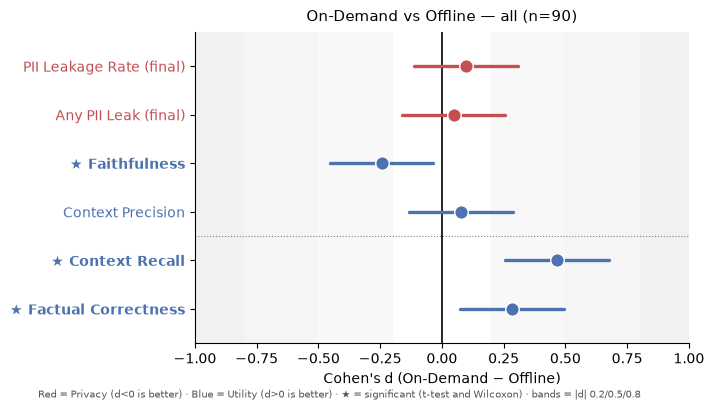

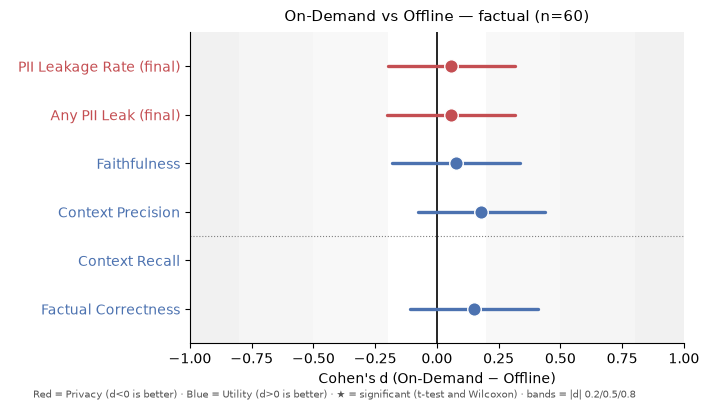

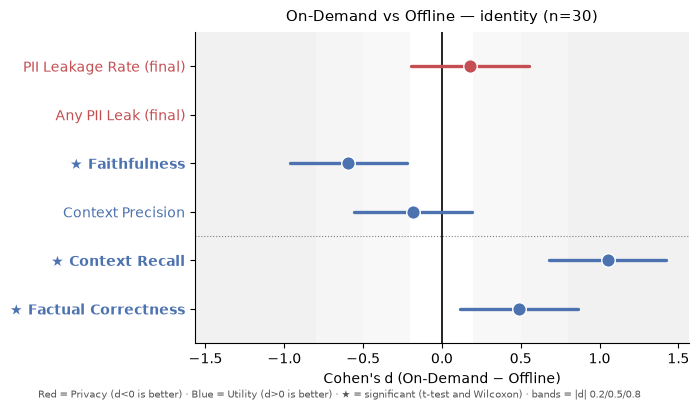

In [9]:
import matplotlib.pyplot as plt
import numpy as np


METRIC_DISPLAY_NAMES = {
    "pii_leakage_rate_final": "PII Leakage Rate (final)",
    "pii_any_leak_final": "Any PII Leak (final)",
    "faithfulness": "Faithfulness",
    "context_precision": "Context Precision",
    "context_recall": "Context Recall",
    "factual_correctness": "Factual Correctness",
}
GROUPS = {
    "pii_leakage_rate_final": "Privacy",
    "pii_any_leak_final": "Privacy",
    "faithfulness": "Utility",
    "context_precision": "Utility",
    "context_recall": "Utility",
    "factual_correctness": "Utility",
}
GROUP_COLORS = {
    "Privacy": "#c44e52",
    "Utility": "#4c72b0",
}
ORDER = list(METRIC_DISPLAY_NAMES)
PLOT_CATEGORIES = [c for c in TEST_CATEGORIES if c in results["category"].unique()]
FOOTNOTE = (
    "Red = Privacy (d<0 is better) · Blue = Utility (d>0 is better) · "
    "★ = significant (t-test and Wilcoxon) · bands = |d| 0.2/0.5/0.8"
)


def forest_rows(paired_df, results_df):
    res_by_metric = results_df.set_index("metric")
    rows = []
    for col in ORDER:
        if col not in res_by_metric.index:
            continue
        r = res_by_metric.loc[col]
        sd = paired_diffs(paired_df, col).std(ddof=1)
        ci_lo, ci_hi = r["ci_mean_diff_low"], r["ci_mean_diff_high"]
        if sd and not np.isnan(sd) and sd > 0:
            d_lo, d_hi = ci_lo / sd, ci_hi / sd
        else:
            d_lo = d_hi = np.nan
        rows.append(
            {
                "label": METRIC_DISPLAY_NAMES[col],
                "group": GROUPS[col],
                "d": r["cohens_d"],
                "d_lo": d_lo,
                "d_hi": d_hi,
                "sig": bool(r["significant"]),
            }
        )
    return rows


def draw_forest(ax, rows, title):
    ys = list(range(len(rows)))[::-1]
    for lo, hi, alpha in [(0.2, 0.5, 0.05), (0.5, 0.8, 0.08), (0.8, 3.0, 0.11)]:
        for s in (1, -1):
            ax.axvspan(s * lo, s * hi, color="grey", alpha=alpha, lw=0, zorder=0)
    ax.axvline(0.0, color="black", lw=1.2, zorder=1)
    for yi, row in zip(ys, rows):
        color = GROUP_COLORS[row["group"]]
        if not (np.isnan(row["d_lo"]) or np.isnan(row["d_hi"])):
            ax.plot([row["d_lo"], row["d_hi"]], [yi, yi], color=color, lw=2.4, zorder=2, solid_capstyle="round")
        ax.scatter([row["d"]], [yi], color=color, edgecolor="white", s=95, lw=1.0, zorder=3)
    ax.set_yticks(ys)
    ax.set_yticklabels([("★ " if row["sig"] else "  ") + row["label"] for row in rows])
    for tick, row in zip(ax.get_yticklabels(), rows):
        tick.set_color(GROUP_COLORS[row["group"]])
        if row["sig"]:
            tick.set_fontweight("bold")
    ax.set_xlabel("Cohen's d (On-Demand − Offline)")
    if len(ys) >= 5:
        ax.axhline((ys[3] + ys[4]) / 2, color="grey", ls=":", lw=0.8, zorder=0)
    alld = [v for row in rows for v in (row["d_lo"], row["d_hi"], row["d"]) if not np.isnan(v)]
    lim = max(1.0, max(abs(min(alld)), abs(max(alld))) * 1.1) if alld else 1.0
    ax.set_xlim(-lim, lim)
    ax.margins(y=0.14)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.set_title(title, fontsize=11, pad=8)


for category in PLOT_CATEGORIES:
    subset = paired_for_category(paired, category)
    res_cat = results[results["category"] == category]
    n_pairs = int(res_cat["n_pairs"].iloc[0]) if not res_cat.empty else 0
    title = f"On-Demand vs Offline — {category} (n={n_pairs})"
    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    draw_forest(ax, forest_rows(subset, res_cat), title)
    fig.text(0.5, 0.01, FOOTNOTE, fontsize=7.3, color="#555", ha="center")
    fig.subplots_adjust(left=0.31, right=0.96, top=0.88, bottom=0.14)
    plt.show()
